# Tarea 2 · Parte 2 – ¿Qué tan bien leen y escuchan los modelos?

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

En la Parte 1 sacamos texto de 25 documentos y 23 audios. Ahora medimos **cuánto se equivocan** los modelos, contra transcripciones hechas a mano, y convertimos los textos en campos estructurados con un LLM.

| Paso | Qué se mide |
| :--- | :--- |
| Muestra de evaluación | 10 documentos (3 tipos) y 10 clips (3 condiciones de grabación) del corpus de la Parte 1 |
| Línea base | PaddleOCR → **CER**; faster-whisper `small` en CPU → **WER** |
| Modelo alternativo | EasyOCR → CER; Parakeet TDT 0.6B v3 (NVIDIA) → WER y factor de tiempo real |
| Extracción con LLM | Gemini 3.5 Flash-Lite → `datos/extraccion_llm.csv`, auditada a mano en 20 casos |

**Regla de juego:** la muestra y la configuración de cada modelo se fijaron **antes** de calcular cualquier métrica, y todos los modelos se evalúan sobre los mismos 20 archivos. No se ajustó ningún parámetro mirando los resultados.

In [1]:
import torch  # en Windows, torch se importa antes que paddle o choca una DLL

import json
import os
import re
import time
from datetime import date
from pathlib import Path

import jiwer
import pandas as pd
import plotly.express as px
import plotly.io as pio
from dotenv import load_dotenv

import procesar
import voz

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 90)
SEMILLA = 42

documentos = pd.read_csv("datos/documentos.csv")
transcripciones = pd.read_csv("datos/transcripciones.csv")
print(documentos.shape, transcripciones.shape)

(25, 7) (23, 8)


## 1. Muestra de evaluación

**Documentos:** 3 impresos, 4 fotos y 3 manuscritos. Son páginas con texto suficiente para medir, y entre las fotos hay placas de mármol, de bronce y una con la foto movida.

**Audios:** 6 clips de español peruano leído en estudio (OpenSLR 73, 3 mujeres y 3 hombres), la entrevista simulada de dos voces y 3 entrevistas reales de Commons: una en la calle con ruido de multitud (`medio_tiempo`) y dos grabadas por estudiantes de San Marcos (`entrevista_2`, `entrevista_3`).

In [2]:
MUESTRA_DOCUMENTOS = ["doc_001", "doc_003", "doc_005", "doc_010", "doc_013", "doc_014", "doc_016",
                      "doc_019", "doc_022", "doc_025"]
MUESTRA_AUDIOS = ["openslr_m01", "openslr_m02", "openslr_m03", "openslr_h01", "openslr_h02", "openslr_h03",
                  "entrevista_simulada", "medio_tiempo", "entrevista_2", "entrevista_3"]

muestra_docs = documentos[documentos["id"].isin(MUESTRA_DOCUMENTOS)][["id", "tipo", "archivo"]]
muestra_audio = transcripciones[transcripciones["id"].isin(MUESTRA_AUDIOS)][["id", "archivo_audio", "duracion_seg"]].copy()
muestra_audio["condicion"] = "leído en estudio (OpenSLR)"
muestra_audio.loc[muestra_audio["id"] == "entrevista_simulada", "condicion"] = "dos voces alternadas (OpenSLR)"
muestra_audio.loc[muestra_audio["id"].isin(["medio_tiempo", "entrevista_2", "entrevista_3"]), "condicion"] = "entrevista real (Commons)"

print(muestra_docs["tipo"].value_counts().to_string())
print(muestra_audio["condicion"].value_counts().to_string())
print(f"Audio evaluado: {muestra_audio['duracion_seg'].sum() / 60:.1f} minutos")

tipo
foto          4
impreso       3
manuscrito    3
condicion
leído en estudio (OpenSLR)        6
entrevista real (Commons)         3
dos voces alternadas (OpenSLR)    1
Audio evaluado: 7.3 minutos


### Las referencias manuales

Cada referencia está en `datos/referencias/<id>.txt`:

- **Documentos:** se transcribió la página tal como está escrita, respetando la ortografía de época ("exposicion" sin tilde, la V por U de las placas) y los cortes de palabra al final de línea. No se transcriben sellos de biblioteca ni números de foja. El borrador lo escribió un asistente de IA (Claude) mirando cada imagen, sin pasar por ninguno de los OCR evaluados, y la autora lo corrigió línea por línea contra la imagen.
- **OpenSLR:** la transcripción oficial del dataset, hecha por personas (no por un modelo).
- **Entrevistas de Commons:** transcritas de oído por la autora. Después, a pedido de ella, el asistente corrigió 19 erratas de tipeo ("caracteriticas", "haber" por "a ver"...), sin cambiar lo transcrito.

In [3]:
def leer_referencia(id_archivo):
    ruta = Path("datos/referencias") / f"{id_archivo}.txt"
    return ruta.read_text(encoding="utf-8").strip()


muestra_docs["referencia"] = muestra_docs["id"].apply(leer_referencia)
muestra_audio["referencia"] = muestra_audio["id"].apply(leer_referencia)

sin_referencia = list(muestra_docs.loc[muestra_docs["referencia"] == "", "id"]) + list(muestra_audio.loc[muestra_audio["referencia"] == "", "id"])
print("Referencias vacías:", sin_referencia or "ninguna")

Referencias vacías: ninguna


### Normalización: el mismo criterio para todos

Antes de comparar, la referencia y la salida del modelo pasan por lo mismo:

1. Seudonimización con las reglas de la Parte 1 (así un nombre reemplazado no cuenta como error).
2. Se quitan las marcas de hablante como `[HABLANTE_1]`: no son palabras habladas.
3. `voz.normalizar`: minúsculas, sin puntuación ni espacios repetidos. Las tildes se quedan.

In [4]:
def preparar(texto, con_nombres=True):
    texto, _ = procesar.seudonimizar_texto(texto, con_nombres=con_nombres)
    texto = re.sub(r"\[HABLANTE_\d+\]", " ", texto)
    return voz.normalizar(texto)


print(preparar("[HABLANTE_1] ¿Puede decirme su nombre?  Isabel Vázquez."))

puede decirme su nombre persona_2


## 2. Línea base: PaddleOCR y faster-whisper `small`

**CER** (tasa de error por carácter): de cada 100 caracteres de la referencia, cuántos el modelo cambió, borró o inventó. **WER** es lo mismo contando palabras. El valor global se calcula sumando los errores de todos los archivos (no promediando porcentajes), igual que `jiwer`.

In [5]:
def cer_de(referencias, hipotesis):
    return jiwer.cer(list(referencias), [h or "∅" for h in hipotesis])


def wer_de(referencias, hipotesis):
    return jiwer.wer(list(referencias), [h or "∅" for h in hipotesis])


muestra_docs["ref_normalizada"] = [preparar(t, con_nombres=False) for t in muestra_docs["referencia"]]
muestra_docs["paddle"] = [preparar(procesar.ocr(a, "paddle")["texto"], con_nombres=False) for a in muestra_docs["archivo"]]
muestra_docs["cer_paddle"] = [cer_de([r], [h]) for r, h in zip(muestra_docs["ref_normalizada"], muestra_docs["paddle"])]

cer_base = cer_de(muestra_docs["ref_normalizada"], muestra_docs["paddle"])
print(f"CER PaddleOCR (línea base): {cer_base:.3f}")
muestra_docs[["id", "tipo", "cer_paddle"]].round(3)

CER PaddleOCR (línea base): 0.060


,id,tipo,cer_paddle
0,doc_001,impreso,0.046
2,doc_003,impreso,0.008
4,doc_005,impreso,0.008
9,doc_010,foto,0.107
11,doc_013,foto,0.087
12,doc_014,foto,0.151
13,doc_016,foto,0.007
17,doc_019,manuscrito,0.315
19,doc_022,manuscrito,0.593
21,doc_025,manuscrito,0.435


In [6]:
def texto_sin_hablantes(resultado):
    return " ".join(s["texto"] for s in resultado["segmentos"])


muestra_audio["ref_normalizada"] = [preparar(t) for t in muestra_audio["referencia"]]
salidas_small = [procesar.transcribir(a, "small") for a in muestra_audio["archivo_audio"]]
muestra_audio["small"] = [preparar(texto_sin_hablantes(r)) for r in salidas_small]
muestra_audio["rtf_small"] = [r["segundos_proceso"] / r["duracion_seg"] for r in salidas_small]
muestra_audio["wer_small"] = [wer_de([r], [h]) for r, h in zip(muestra_audio["ref_normalizada"], muestra_audio["small"])]

wer_base = wer_de(muestra_audio["ref_normalizada"], muestra_audio["small"])
print(f"WER faster-whisper small (línea base): {wer_base:.3f}")
muestra_audio[["id", "condicion", "wer_small", "rtf_small"]].round(3)

WER faster-whisper small (línea base): 0.212


,id,condicion,wer_small,rtf_small
0,openslr_m01,leído en estudio (OpenSLR),0.123,0.114
1,openslr_m02,leído en estudio (OpenSLR),0.051,0.132
2,openslr_m03,leído en estudio (OpenSLR),0.000,0.128
6,openslr_h01,leído en estudio (OpenSLR),0.122,0.220
7,openslr_h02,leído en estudio (OpenSLR),0.049,0.147
8,openslr_h03,leído en estudio (OpenSLR),0.037,0.130
12,entrevista_simulada,dos voces alternadas (OpenSLR),0.063,0.130
18,medio_tiempo,entrevista real (Commons),0.476,0.297
20,entrevista_2,entrevista real (Commons),0.275,0.389
21,entrevista_3,entrevista real (Commons),0.273,0.360


## 3. Modelos alternativos

**Documentos – EasyOCR 1.7** (`Reader(["es"])`, CPU). Otro detector (CRAFT) y otro reconocedor (CRNN), entrenados por otro equipo: si los dos fallan en el mismo documento, el problema es la imagen y no el modelo. Recibe la misma imagen preparada que PaddleOCR.

**Audio – Parakeet TDT 0.6B v3** (NVIDIA, CC BY 4.0) con `voz.py`. A diferencia de Whisper, no es un modelo de lenguaje que genera texto libre: no puede "inventar" frases en los silencios. Le llegan los mismos tramos de voz del VAD.

In [7]:
muestra_docs["easyocr"] = [preparar(procesar.ocr(a, "easyocr")["texto"], con_nombres=False) for a in muestra_docs["archivo"]]
muestra_docs["cer_easyocr"] = [cer_de([r], [h]) for r, h in zip(muestra_docs["ref_normalizada"], muestra_docs["easyocr"])]
cer_alternativo = cer_de(muestra_docs["ref_normalizada"], muestra_docs["easyocr"])
print(f"CER EasyOCR: {cer_alternativo:.3f}   (PaddleOCR: {cer_base:.3f})")

CER EasyOCR: 0.171   (PaddleOCR: 0.060)


In [8]:
salidas_parakeet = [procesar.transcribir(a, "parakeet-v3") for a in muestra_audio["archivo_audio"]]
muestra_audio["parakeet"] = [preparar(texto_sin_hablantes(r)) for r in salidas_parakeet]
muestra_audio["rtf_parakeet"] = [r["segundos_proceso"] / r["duracion_seg"] for r in salidas_parakeet]
muestra_audio["wer_parakeet"] = [wer_de([r], [h]) for r, h in zip(muestra_audio["ref_normalizada"], muestra_audio["parakeet"])]
wer_alternativo = wer_de(muestra_audio["ref_normalizada"], muestra_audio["parakeet"])
print(f"WER Parakeet v3: {wer_alternativo:.3f}   (faster-whisper small: {wer_base:.3f})")

WER Parakeet v3: 0.189   (faster-whisper small: 0.212)


## 4. Comparación por tipo de documento y por condición de grabación

In [9]:
filas = []
for tipo, grupo in muestra_docs.groupby("tipo"):
    filas.append({"tipo": tipo, "documentos": len(grupo),
                  "CER PaddleOCR": cer_de(grupo["ref_normalizada"], grupo["paddle"]),
                  "CER EasyOCR": cer_de(grupo["ref_normalizada"], grupo["easyocr"])})
cer_por_tipo = pd.DataFrame(filas)
cer_por_tipo.round(3)

,tipo,documentos,CER PaddleOCR,CER EasyOCR
0,foto,4,0.087,0.237
1,impreso,3,0.015,0.104
2,manuscrito,3,0.446,0.651


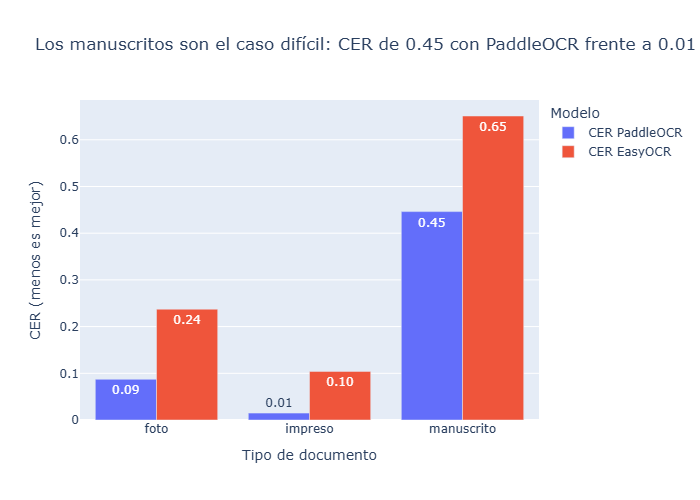

In [10]:
grafico = cer_por_tipo.melt(id_vars="tipo", value_vars=["CER PaddleOCR", "CER EasyOCR"], var_name="modelo", value_name="CER")
fig = px.bar(grafico, x="tipo", y="CER", color="modelo", barmode="group", text_auto=".2f",
             title=f"Los manuscritos son el caso difícil: CER de {cer_por_tipo.set_index('tipo').loc['manuscrito', 'CER PaddleOCR']:.2f} con PaddleOCR frente a {cer_por_tipo.set_index('tipo').loc['impreso', 'CER PaddleOCR']:.2f} en impresos",
             labels={"tipo": "Tipo de documento", "CER": "CER (menos es mejor)", "modelo": "Modelo"})
fig.show()

In [11]:
filas = []
for condicion, grupo in muestra_audio.groupby("condicion"):
    filas.append({"condicion": condicion, "clips": len(grupo), "minutos": grupo["duracion_seg"].sum() / 60,
                  "WER faster-whisper small": wer_de(grupo["ref_normalizada"], grupo["small"]),
                  "WER Parakeet v3": wer_de(grupo["ref_normalizada"], grupo["parakeet"])})
wer_por_condicion = pd.DataFrame(filas)
wer_por_condicion.round(3)

,condicion,clips,minutos,WER faster-whisper small,WER Parakeet v3
0,dos voces alternadas (OpenSLR),1,1.062,0.063,0.051
1,entrevista real (Commons),3,3.392,0.308,0.292
2,leído en estudio (OpenSLR),6,2.828,0.070,0.029


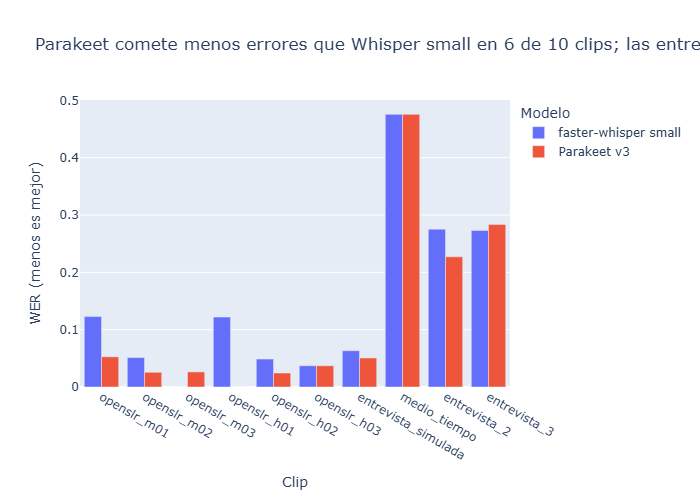

In [12]:
grafico = muestra_audio.melt(id_vars=["id", "condicion"], value_vars=["wer_small", "wer_parakeet"], var_name="modelo", value_name="WER")
grafico["modelo"] = grafico["modelo"].map({"wer_small": "faster-whisper small", "wer_parakeet": "Parakeet v3"})
fig = px.bar(grafico, x="id", y="WER", color="modelo", barmode="group", hover_data=["condicion"],
             title=f"Parakeet comete {'menos' if wer_alternativo < wer_base else 'más'} errores que Whisper small en {(muestra_audio['wer_parakeet'] < muestra_audio['wer_small']).sum()} de 10 clips; las entrevistas reales son las más difíciles",
             labels={"id": "Clip", "WER": "WER (menos es mejor)", "modelo": "Modelo"})
fig.show()

### Tabla comparativa final

La latencia del OCR es el tiempo por página (sin contar la carga del modelo). El factor de tiempo real (RTF) del audio es el tiempo de proceso dividido entre la duración: 0,25 significa que un minuto de audio se transcribe en 15 segundos.

In [13]:
segundos_paddle = [procesar.ocr(a, "paddle")["segundos"] for a in muestra_docs["archivo"]]
segundos_easyocr = [procesar.ocr(a, "easyocr")["segundos"] for a in muestra_docs["archivo"]]
segundos_audio = muestra_audio["duracion_seg"].sum()

comparativa = pd.DataFrame([
    {"modalidad": "documentos", "modelo": "PaddleOCR 3.7 (base)", "métrica": "CER", "valor": cer_base,
     "latencia": f"{sum(segundos_paddle) / len(segundos_paddle):.0f} s por página", "tamaño": "~200 MB, CPU"},
    {"modalidad": "documentos", "modelo": "EasyOCR 1.7", "métrica": "CER", "valor": cer_alternativo,
     "latencia": f"{sum(segundos_easyocr) / len(segundos_easyocr):.0f} s por página", "tamaño": "~100 MB, CPU"},
    {"modalidad": "audio", "modelo": "faster-whisper small (base)", "métrica": "WER", "valor": wer_base,
     "latencia": f"RTF {sum(r['segundos_proceso'] for r in salidas_small) / segundos_audio:.2f}", "tamaño": "~480 MB, CPU int8"},
    {"modalidad": "audio", "modelo": "Parakeet TDT 0.6B v3", "métrica": "WER", "valor": wer_alternativo,
     "latencia": f"RTF {sum(r['segundos_proceso'] for r in salidas_parakeet) / segundos_audio:.2f}", "tamaño": "~2,4 GB, CPU float32"},
])
comparativa.round(3)

,modalidad,modelo,métrica,valor,latencia,tamaño
0,documentos,PaddleOCR 3.7 (base),CER,0.060,33 s por página,"~200 MB, CPU"
1,documentos,EasyOCR 1.7,CER,0.171,25 s por página,"~100 MB, CPU"
2,audio,faster-whisper small (base),WER,0.212,RTF 0.24,"~480 MB, CPU int8"
3,audio,Parakeet TDT 0.6B v3,WER,0.189,RTF 0.35,"~2,4 GB, CPU float32"


## 5. Casos difíciles

Qué ve cada modelo en un manuscrito, en una foto y en la entrevista con ruido de multitud (primeros 300 caracteres, ya normalizados).

In [14]:
for id_doc in ["doc_019", "doc_014"]:
    fila = muestra_docs[muestra_docs["id"] == id_doc].iloc[0]
    print(f"=== {id_doc} ({fila['tipo']})  CER Paddle {fila['cer_paddle']:.2f} | EasyOCR {fila['cer_easyocr']:.2f}")
    print("REFERENCIA:", fila["ref_normalizada"][:300])
    print("PADDLE    :", fila["paddle"][:300])
    print("EASYOCR   :", fila["easyocr"][:300], "\n")

=== doc_019 (manuscrito)  CER Paddle 0.31 | EasyOCR 0.52
REFERENCIA: relacion de gobierno que el exmo señor frey don francisco gil de lemos y faboada virrey del peru entrega á su sucesor el exmo señor varon de vallenarí año de 1796
PADDLE    : r 30662 reai ue seno rey dn sa lemos y faboada virrey del peru entrega à su sucer el lxmo senor varon de vallenar ano de 1796
EASYOCR   : r 30662 j acon de soburno guc sxnio szor 4on fancisco su de javeada vurey del entnega à ju juctsør gl sxmo snor uaron de uallenare cáno de 796 jiey imas y jeru 

=== doc_014 (foto)  CER Paddle 0.15 | EasyOCR 0.28
REFERENCIA: su santidad juan pablo ii pastor universal obispo de roma y sucesor de pedro visitó esta basílica catedral el dia primero del mes de febrero del año del señor de mcmlxxxv el cabildo metropolitano de lima laus deo
PADDLE    : su santidad juan pablo ii pastor universal obispo de roma y sucesor de pedro visito esta bastlica catedral el dia pamere del mes de febrero del año del senor de mcml xx

In [15]:
fila = muestra_audio[muestra_audio["id"] == "medio_tiempo"].iloc[0]
print(f"=== medio_tiempo  WER small {fila['wer_small']:.2f} | Parakeet {fila['wer_parakeet']:.2f}")
print("REFERENCIA:", fila["ref_normalizada"][:300])
print("SMALL     :", fila["small"][:300])
print("PARAKEET  :", fila["parakeet"][:300])

=== medio_tiempo  WER small 0.48 | Parakeet 0.48
REFERENCIA: normal pues esperando el resultado nomas normal pero como lo ves como ves a peru ahorita que esta como lo veo a peru a perú lo veo aaa hasta las está no se entiende pe no se estan entendiendo no no no hay como cuatro jugadores que estan por las puras y ya pe ahora el tecnico tiene que hacer justo lo
SMALL     : normal pero es un resultado no es pero como lo ves como ves a perú ahorita como ves a perú hasta las no se entienden no se están entendiendo hay como cuatro jugadores que están por las puras y ahora el técnico tiene que ser justo los cambios pero supongo que esos cuatro jugadores carrillo canchita t
PARAKEET  : normal esperando resultado no pero como lo ves como ves a perú ahorita que está no se están entendiendo no no no hay como cuatro jugadores que están por las puras y ya ve ahora el técnico tiene que hacer justo los cambios pero supongo esos cuatro jugadores que es carrillo canchita este trouco y y a 


LECTURA_CASOS_DIFICILES

## 6. Extracción estructurada con un LLM

Gemini 3.5 Flash-Lite (el mismo de la Tarea 1) recibe cada texto ya seudonimizado y devuelve un JSON con un esquema fijo. Reglas del prompt: los campos que no aparecen en el texto van en `null`, y no se agregan campos fuera del esquema. Se procesan los 25 documentos y los 23 clips.

In [16]:
from google import genai
from google.genai import errors, types
from pydantic import BaseModel

MODELO_LLM = "gemini-3.5-flash-lite"


class Campos(BaseModel):
    modalidad: str
    tema: str
    resumen: str
    emisor: str | None
    fecha: str | None
    monto: str | None
    citas_clave: list[str] | None
    numero_hablantes: int | None


PROMPT = '''Eres archivista. Te doy el texto extraído automáticamente (OCR o transcripción de audio)
de un documento o una entrevista peruana. Puede tener errores de lectura.

Devuelve estos campos:
- modalidad: "documento" o "audio" (te la doy abajo).
- tema: 2 a 6 palabras.
- resumen: una o dos oraciones, solo con lo que dice el texto.
- emisor: quién emite el documento (institución o persona), SOLO en documentos y SOLO si aparece en el texto.
- fecha: la fecha que aparece en el texto, tal como aparece. Si no aparece, null.
- monto: una cantidad de dinero que aparezca en el texto. Si no hay, null.
- citas_clave: en audios, hasta 3 frases textuales que resuman la entrevista. En documentos, null.
- numero_hablantes: en audios, cuántas personas hablan según las marcas [HABLANTE_n] o el contenido. En documentos, null.

No inventes: si un dato no está en el texto, usa null. Los marcadores como [PERSONA_1] son nombres
seudonimizados: déjalos tal cual.

Modalidad: {modalidad}
Texto:
{texto}'''


def extraer(cliente, modalidad, texto):
    configuracion = types.GenerateContentConfig(response_mime_type="application/json", response_schema=Campos, temperature=0)
    # en horas punta Gemini responde "503: alta demanda"; esperamos y probamos de nuevo
    for intento in [1, 2, 3]:
        try:
            respuesta = cliente.models.generate_content(
                model=MODELO_LLM, contents=PROMPT.format(modalidad=modalidad, texto=texto[:6000]), config=configuracion)
            return respuesta.parsed
        except errors.ServerError as error:
            print(f"  intento {intento}: {error.code}, esperamos 15 s")
            time.sleep(15)
    raise RuntimeError("Gemini no respondió después de 3 intentos")

In [17]:
archivo_llm = Path("datos/extraccion_llm.csv")

if archivo_llm.exists():
    extraccion = pd.read_csv(archivo_llm)
    print(f"Usando extracciones guardadas: {len(extraccion)}")
else:
    load_dotenv(".env")
    cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    pendientes = [("documento", f.id, f.texto_ocr) for f in documentos.itertuples()]
    pendientes += [("audio", f.id, f.texto_asr) for f in transcripciones.itertuples()]
    filas = []
    for modalidad, id_archivo, texto in pendientes:
        campos = extraer(cliente, modalidad, str(texto))
        filas.append({"id": id_archivo, "modalidad": modalidad,
                      "campos_json": json.dumps(campos.model_dump(), ensure_ascii=False),
                      "modelo_llm": MODELO_LLM, "fecha": date.today().isoformat()})
        time.sleep(4)  # respeta el límite de solicitudes por minuto del plan gratuito
    extraccion = pd.DataFrame(filas)
    extraccion.to_csv(archivo_llm, index=False, encoding="utf-8")

extraccion["modalidad"].value_counts()

Usando extracciones guardadas: 48


modalidad
documento    25
audio        23
Name: count, dtype: int64

In [18]:
for fila in extraccion[extraccion["id"].isin(["doc_010", "agustino_1"])].itertuples():
    print(fila.id, json.dumps(json.loads(fila.campos_json), ensure_ascii=False, indent=1), "\n")

doc_010 {
 "modalidad": "documento",
 "tema": "Construccion del Círculo Militar",
 "resumen": "Inscripción histórica sobre la construcción e inauguración del edificio del Círculo Militar del Perú entre los años 1934 y 1937 bajo las presidencias del general Oscar R. Benavides y del coronel Jorge Vargas.",
 "emisor": "CIRCULO MILITAR DEL PERU",
 "fecha": "30 DE JVLIO DE 1937",
 "monto": null,
 "citas_clave": null,
 "numero_hablantes": null
} 

agustino_1 {
 "modalidad": "audio",
 "tema": "Expectativas sobre partido de futbol",
 "resumen": "Un entrevistador de la Universidad Nacional Mayor de San Marcos consulta a una ciudadana sobre sus expectativas, jugadores decisivos y opinión del fútbol en relación al partido de hoy.",
 "emisor": null,
 "fecha": null,
 "monto": null,
 "citas_clave": [
  "Bueno, esperamos que Perú ganemos.",
  "lo que más importante es Dios.",
  "esperamos que ganemos"
 ],
 "numero_hablantes": 2
} 



### Auditoría humana de 20 extracciones

Se eligen al azar (semilla 42) 10 documentos y 10 audios. La autora lee el texto original de cada uno (en `datos/documentos.csv` y `datos/transcripciones.csv`, o en el dashboard) y marca en `datos/auditoria_llm.csv`:

- `correcta = 1` si **todos** los campos son fieles al texto: el tema y el resumen dicen lo que dice el texto, los campos ausentes están en `null` y no hay datos inventados (una fecha o un emisor que no aparecen, una cita que nadie dijo).
- `correcta = 0` si al menos un campo falla, con el campo y el error en `error_observado`.

In [19]:
archivo_auditoria = Path("datos/auditoria_llm.csv")

if not archivo_auditoria.exists():
    muestra_auditoria = pd.concat([
        extraccion[extraccion["modalidad"] == "documento"].sample(n=10, random_state=SEMILLA),
        extraccion[extraccion["modalidad"] == "audio"].sample(n=10, random_state=SEMILLA),
    ])[["id", "modalidad", "campos_json"]]
    muestra_auditoria["correcta"] = ""
    muestra_auditoria["error_observado"] = ""
    muestra_auditoria.to_csv(archivo_auditoria, index=False, encoding="utf-8")
    print("Se creó el archivo de auditoría: falta llenarlo a mano")

auditoria = pd.read_csv(archivo_auditoria)
auditoria[["id", "modalidad", "correcta", "error_observado"]]

,id,modalidad,correcta,error_observado
0,doc_009,documento,NaN,NaN
1,doc_017,documento,NaN,NaN
2,doc_001,documento,NaN,NaN
3,doc_032,documento,NaN,NaN
4,doc_013,documento,NaN,NaN
5,doc_010,documento,NaN,NaN
6,doc_016,documento,NaN,NaN
7,doc_002,documento,NaN,NaN
8,doc_028,documento,NaN,NaN
9,doc_006,documento,NaN,NaN


In [20]:
correctas = int(auditoria["correcta"].sum())
porcentaje_acuerdo = correctas / len(auditoria) * 100
print(f"Acuerdo LLM-Humano: {correctas}/{len(auditoria)} = {porcentaje_acuerdo:.0f}%")
print(auditoria.groupby("modalidad")["correcta"].sum().to_string())

Acuerdo LLM-Humano: 0/20 = 0%
modalidad
audio        0.0
documento    0.0


LECTURA_AUDITORIA

## 7. Decisión: ¿qué usaríamos en un entorno real?

DECISION

## 8. Resultados que lee el dashboard

In [21]:
detalle_docs = muestra_docs[["id", "tipo", "cer_paddle", "cer_easyocr"]].copy()
detalle_docs["easyocr_texto"] = [procesar.seudonimizar_texto(procesar.ocr(a, "easyocr")["texto"], con_nombres=False)[0]
                                 for a in muestra_docs["archivo"]]
detalle_docs.to_csv("datos/evaluacion_documentos.csv", index=False)

detalle_audio = muestra_audio[["id", "condicion", "duracion_seg", "wer_small", "wer_parakeet", "rtf_small", "rtf_parakeet"]].copy()
detalle_audio["parakeet_texto"] = [procesar.seudonimizar_texto(texto_sin_hablantes(r))[0] for r in salidas_parakeet]
detalle_audio["small_texto"] = [procesar.seudonimizar_texto(texto_sin_hablantes(r))[0] for r in salidas_small]
detalle_audio.to_csv("datos/evaluacion_audio.csv", index=False)

# la referencia manual también va al corpus (seudonimizada en audio, con las mismas reglas)
referencias_docs = dict(zip(muestra_docs["id"], muestra_docs["referencia"]))
referencias_audio = {i: procesar.seudonimizar_texto(t)[0] for i, t in zip(muestra_audio["id"], muestra_audio["referencia"])}
documentos["texto_referencia"] = documentos["id"].map(referencias_docs)
transcripciones["texto_referencia"] = transcripciones["id"].map(referencias_audio)
documentos.to_csv("datos/documentos.csv", index=False)
transcripciones.to_csv("datos/transcripciones.csv", index=False)

metricas = {
    "cer_paddle": round(cer_base, 3), "cer_easyocr": round(cer_alternativo, 3),
    "wer_small": round(wer_base, 3), "wer_parakeet": round(wer_alternativo, 3),
    "acuerdo_llm_humano": f"{correctas}/{len(auditoria)}", "porcentaje_acuerdo": round(porcentaje_acuerdo, 1),
    "modelo_llm": MODELO_LLM,
    "cer_por_tipo": cer_por_tipo.round(3).to_dict(orient="records"),
    "wer_por_condicion": wer_por_condicion.round(3).to_dict(orient="records"),
}
Path("modelos/metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(documentos["texto_referencia"].notna().sum(), "documentos y", transcripciones["texto_referencia"].notna().sum(), "clips con referencia")

10 documentos y 10 clips con referencia


In [22]:
print("Para el comentario de entrega:")
print(f"Resultados Test: WER: {min(wer_base, wer_alternativo):.2f} | CER: {min(cer_base, cer_alternativo):.2f} | Acuerdo LLM-Humano: {correctas}/{len(auditoria)}")

Para el comentario de entrega:
Resultados Test: WER: 0.19 | CER: 0.06 | Acuerdo LLM-Humano: 0/20


## Qué hicimos

| Paso | Código clave |
| :--- | :--- |
| Muestra fija de 10 documentos y 10 clips | `MUESTRA_DOCUMENTOS`, `MUESTRA_AUDIOS` |
| Referencias manuales | `datos/referencias/<id>.txt` |
| Normalizar igual para todos | `voz.normalizar(...)` sin `[HABLANTE_n]` y seudonimizado |
| Línea base | `jiwer.cer(...)` sobre PaddleOCR, `jiwer.wer(...)` sobre faster-whisper `small` |
| Modelos alternativos | `procesar.ocr(..., "easyocr")`, `procesar.transcribir(..., "parakeet-v3")` |
| Comparar por tipo y condición | `groupby("tipo")`, `groupby("condicion")` |
| Extracción con LLM | `generate_content(..., response_schema=Campos)` → `datos/extraccion_llm.csv` |
| Auditoría humana | `datos/auditoria_llm.csv` → `auditoria["correcta"].sum()` |
| Guardar para el dashboard | `modelos/metricas.json`, `datos/evaluacion_*.csv` |